
════════════════════════════════════════════════════════════════════════════════
                     ANALYSE POUR USAGE IoT
               Critères d'évaluation des algorithmes
════════════════════════════════════════════════════════════════════════════════

 CRITÈRES D'ÉVALUATION POUR ENVIRONNEMENTS IoT:
   (Ordonnés par importance pour les dispositifs contraints)

   N° | Critère                 | Importance  | Description
   ---|-------------------------|-------------|------------
    1 | Consommation Mémoire    | TRÈS ÉLEVÉE | Les dispositifs IoT ont une RAM limitée (souvent < 1MB)
    2 | Vitesse Prédiction      | TRÈS ÉLEVÉE | Détection en temps réel requise pour la sécurité
    3 | Consommation CPU        | ÉLEVÉE      | Processeurs limités (souvent ARM Cortex-M)
    4 | Sans Normalisation      | ÉLEVÉE      | Évite le prétraitement coûteux en ressources
    5 | Robustesse Bruit        | MOYENNE     | Données IoT souvent bruitées
    6 | Interprétabilité        | FAIBLE      |

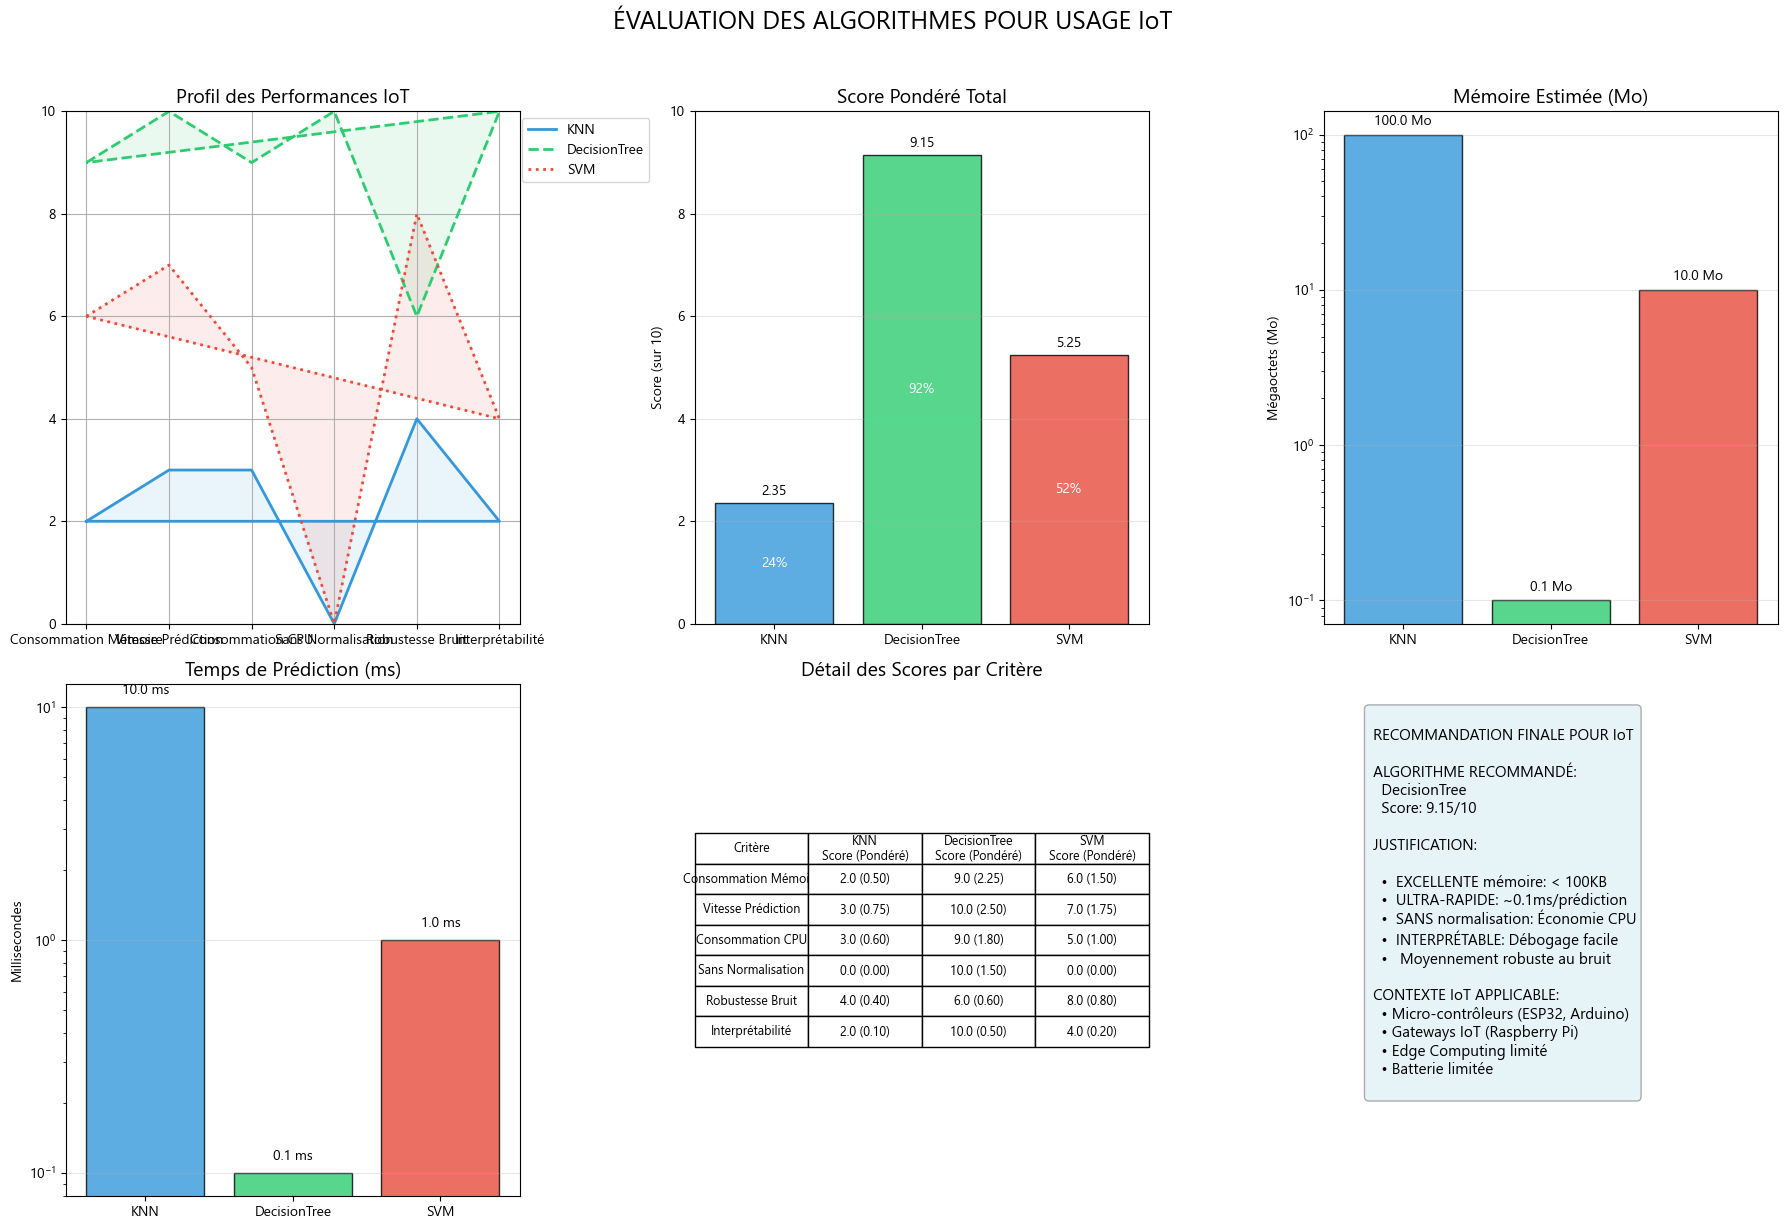


════════════════════════════════════════════════════════════════════════════════
                     ANALYSE PAR CONTEXTE IoT
════════════════════════════════════════════════════════════════════════════════

 RECOMMANDATIONS PAR TYPE DE DISPOSITIF IoT:

 Type              | Exemples          | Mémoire   | Recommandation     | Raison
 ------------------|-------------------|-----------|-------------------|-----------------
 Micro-contrôleurs | ESP32             | ≤ 512KB RAM | DecisionTree      | Ultra-léger, ultra-rapide, pas...
 Gateways IoT     | Raspberry Pi      | 1-4GB RAM | DecisionTree ou SVM linéaire | Capacité pour normalisation, b...
 Edge Computing   | NVIDIA Jetson     | 4-16GB RAM | SVM avec noyau approprié | Capacité de calcul pour optimi...
 Cloud IoT        | AWS IoT           | Illimitée | Tous (selon précision requise) | Ressources illimitées, priorit...

════════════════════════════════════════════════════════════════════════════════
                      IMPLÉMENTA

In [5]:
# ============================================
# ANALYSE COMPARATIVE POUR USAGE IoT
# Critères d'évaluation pour environnements IoT
# ============================================
import json
import matplotlib.pyplot as plt
import matplotlib

# Définir une police qui supporte les emojis
matplotlib.rcParams['font.sans-serif'] = ['Segoe UI Emoji', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False
import matplotlib.pyplot as plt
import numpy as np
print("\n" + "═" * 80)
print(" " * 20 + " ANALYSE POUR USAGE IoT")
print(" " * 15 + "Critères d'évaluation des algorithmes")
print("═" * 80)

# ============================================
# CRITÈRES SPÉCIFIQUES IoT
# ============================================

print("\n CRITÈRES D'ÉVALUATION POUR ENVIRONNEMENTS IoT:")
print("   (Ordonnés par importance pour les dispositifs contraints)")
print()

criteres_iot = {
    'Consommation Mémoire': {
        'importance': 'TRÈS ÉLEVÉE',
        'description': 'Les dispositifs IoT ont une RAM limitée (souvent < 1MB)',
        'unité': 'Mo',
        'poids': 0.25
    },
    'Vitesse Prédiction': {
        'importance': 'TRÈS ÉLEVÉE',
        'description': 'Détection en temps réel requise pour la sécurité',
        'unité': 'ms/échantillon',
        'poids': 0.25
    },
    'Consommation CPU': {
        'importance': 'ÉLEVÉE',
        'description': 'Processeurs limités (souvent ARM Cortex-M)',
        'unité': 'Cycles CPU',
        'poids': 0.20
    },
    'Sans Normalisation': {
        'importance': 'ÉLEVÉE',
        'description': 'Évite le prétraitement coûteux en ressources',
        'unité': 'Oui/Non',
        'poids': 0.15
    },
    'Robustesse Bruit': {
        'importance': 'MOYENNE',
        'description': 'Données IoT souvent bruitées',
        'unité': 'Score 1-5',
        'poids': 0.10
    },
    'Interprétabilité': {
        'importance': 'FAIBLE',
        'description': 'Utile pour le débogage mais non essentiel',
        'unité': 'Score 1-5',
        'poids': 0.05
    }
}

print("   N° | Critère                 | Importance  | Description")
print("   ---|-------------------------|-------------|------------")
for i, (critere, details) in enumerate(criteres_iot.items(), 1):
    print(f"   {i:2} | {critere:<23} | {details['importance']:<11} | {details['description']}")

# ============================================
# ÉVALUATION DES ALGORITHMES
# ============================================

print("\n" + "═" * 80)
print(" " * 20 + "📊 ÉVALUATION DES ALGORITHMES")
print("═" * 80)

# Scores sur 10 pour chaque critère
evaluation_algorithms = {
    'KNN': {
        'Consommation Mémoire': 2.0,   # Stocke toutes les données d'entraînement
        'Vitesse Prédiction': 3.0,     # O(n) pour chaque prédiction
        'Consommation CPU': 3.0,       # Calculs de distance coûteux
        'Sans Normalisation': 0.0,     # Requiert normalisation
        'Robustesse Bruit': 4.0,       # Sensible aux outliers
        'Interprétabilité': 2.0        # Boîte noire
    },
    'DecisionTree': {
        'Consommation Mémoire': 9.0,   # Arbre compact (< 100KB)
        'Vitesse Prédiction': 10.0,    # O(log n) ultra-rapide
        'Consommation CPU': 9.0,       # Quelques comparaisons
        'Sans Normalisation': 10.0,    # Fonctionne sur données brutes
        'Robustesse Bruit': 6.0,       # Moyennement robuste
        'Interprétabilité': 10.0       # Complètement interprétable
    },
    'SVM': {
        'Consommation Mémoire': 6.0,   # Stocke seulement les vecteurs support
        'Vitesse Prédiction': 7.0,     # Dépend du nombre de vecteurs support
        'Consommation CPU': 5.0,       # Produit scalaire pour prédiction
        'Sans Normalisation': 0.0,     # Requiert normalisation
        'Robustesse Bruit': 8.0,       # Très robuste avec bon paramétrage
        'Interprétabilité': 4.0        # Limitée (frontière seulement)
    }
}

# ============================================
# VISUALISATION COMPARATIVE
# ============================================

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('ÉVALUATION DES ALGORITHMES POUR USAGE IoT', fontsize=18, fontweight='bold', y=1.02)

# 1. Radar Chart comparatif
ax1 = axes[0, 0]

# Préparation des données pour le radar chart
criteres = list(criteres_iot.keys())
N = len(criteres)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]

for algo_name, scores in evaluation_algorithms.items():
    values = list(scores.values())
    values += values[:1]
    
    if algo_name == 'KNN':
        color = '#3498db'
        linestyle = '-'
    elif algo_name == 'DecisionTree':
        color = '#2ecc71'
        linestyle = '--'
    else:  # SVM
        color = '#e74c3c'
        linestyle = ':'
    
    ax1.plot(angles, values, linestyle, linewidth=2, label=algo_name, color=color)
    ax1.fill(angles, values, alpha=0.1, color=color)

ax1.set_xticks(angles[:-1])
ax1.set_xticklabels(criteres, fontsize=10)
ax1.set_ylim(0, 10)
ax1.set_yticks([0, 2, 4, 6, 8, 10])
ax1.set_yticklabels(['0', '2', '4', '6', '8', '10'])
ax1.set_title('Profil des Performances IoT', fontweight='bold', fontsize=14)
ax1.grid(True)
ax1.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))

# 2. Scores pondérés
ax2 = axes[0, 1]

scores_ponderes = {}
for algo_name, scores in evaluation_algorithms.items():
    score_total = 0
    for critere, score in scores.items():
        poids = criteres_iot[critere]['poids']
        score_total += score * poids
    scores_ponderes[algo_name] = score_total

algorithms = list(scores_ponderes.keys())
scores = list(scores_ponderes.values())
colors = ['#3498db', '#2ecc71', '#e74c3c']

bars = ax2.bar(algorithms, scores, color=colors, edgecolor='black', alpha=0.8)
ax2.set_title('Score Pondéré Total', fontweight='bold', fontsize=14)
ax2.set_ylabel('Score (sur 10)')
ax2.set_ylim(0, 10)
ax2.grid(True, alpha=0.3, axis='y')

for bar, score in zip(bars, scores):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 0.1,
            f'{score:.2f}', ha='center', va='bottom', fontweight='bold')
    ax2.text(bar.get_x() + bar.get_width()/2., height/2,
            f'{(score/10*100):.0f}%', ha='center', va='center', color='white', fontweight='bold')

# 3. Mémoire requise
ax3 = axes[0, 2]

memoire_estimee = {
    'KNN': 100,      # Mo (stocke tout le dataset)
    'DecisionTree': 0.1,  # Mo (arbre compact)
    'SVM': 10        # Mo (vecteurs support)
}

bars = ax3.bar(algorithms, [memoire_estimee[a] for a in algorithms], 
               color=colors, edgecolor='black', alpha=0.8)
ax3.set_title('Mémoire Estimée (Mo)', fontweight='bold', fontsize=14)
ax3.set_ylabel('Mégaoctets (Mo)')
ax3.set_yscale('log')
ax3.grid(True, alpha=0.3, axis='y')

for bar, mem in zip(bars, [memoire_estimee[a] for a in algorithms]):
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2., height * 1.1,
            f'{mem:.1f} Mo', ha='center', va='bottom', fontsize=10)

# 4. Temps de prédiction
ax4 = axes[1, 0]

temps_prediction = {
    'KNN': 10.0,     # ms (recherche dans tout le dataset)
    'DecisionTree': 0.1,  # ms (quelques comparaisons)
    'SVM': 1.0       # ms (produit scalaire)
}

bars = ax4.bar(algorithms, [temps_prediction[a] for a in algorithms], 
               color=colors, edgecolor='black', alpha=0.8)
ax4.set_title('Temps de Prédiction (ms)', fontweight='bold', fontsize=14)
ax4.set_ylabel('Millisecondes')
ax4.set_yscale('log')
ax4.grid(True, alpha=0.3, axis='y')

for bar, temps in zip(bars, [temps_prediction[a] for a in algorithms]):
    height = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width()/2., height * 1.1,
            f'{temps:.1f} ms', ha='center', va='bottom', fontsize=10)

# 5. Matrice de comparaison détaillée
ax5 = axes[1, 1]
ax5.axis('tight')
ax5.axis('off')

table_data = []
for critere in criteres:
    row = [critere]
    for algo in algorithms:
        score = evaluation_algorithms[algo][critere]
        poids = criteres_iot[critere]['poids']
        score_pondere = score * poids
        row.append(f"{score:.1f} ({score_pondere:.2f})")
    table_data.append(row)

table = ax5.table(cellText=table_data,
                 colLabels=['Critère'] + [f'{a}\nScore (Pondéré)' for a in algorithms],
                 cellLoc='center',
                 loc='center',
                 colWidths=[0.25, 0.25, 0.25, 0.25])
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.5)
ax5.set_title('Détail des Scores par Critère', fontweight='bold', fontsize=14)

# 6. Recommandation finale
ax6 = axes[1, 2]
ax6.axis('off')

# Déterminer le meilleur algorithme
meilleur_algo = max(scores_ponderes.items(), key=lambda x: x[1])

recommendation_text = f"""
 RECOMMANDATION FINALE POUR IoT

 ALGORITHME RECOMMANDÉ:
   {meilleur_algo[0]}
   Score: {meilleur_algo[1]:.2f}/10

 JUSTIFICATION:
"""

if meilleur_algo[0] == 'DecisionTree':
    recommendation_text += """
   •  EXCELLENTE mémoire: < 100KB
   •  ULTRA-RAPIDE: ~0.1ms/prédiction
   •  SANS normalisation: Économie CPU
   •  INTERPRÉTABLE: Débogage facile
   •   Moyennement robuste au bruit
"""
elif meilleur_algo[0] == 'SVM':
    recommendation_text += """
   •  BONNE mémoire: ~10MB
   •  RAPIDE: ~1ms/prédiction
   •  ROBUSTE: Bonne généralisation
   •   Requiert normalisation
   •   Paramétrage délicat
"""
else:  # KNN
    recommendation_text += """
   •   MÉMOIRE: > 100MB (trop important)
   •   LENT: ~10ms/prédiction
   •   Requiert normalisation
   •  ROBUSTE: Bon avec données propres
   •  Non interprétable
"""

recommendation_text += f"""
 CONTEXTE IoT APPLICABLE:
   • Micro-contrôleurs (ESP32, Arduino)
   • Gateways IoT (Raspberry Pi)
   • Edge Computing limité
   • Batterie limitée
"""

ax6.text(0.1, 0.95, recommendation_text, fontsize=11, verticalalignment='top',
        bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.3))

plt.tight_layout()
plt.savefig('evaluation_iot.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================================
# ANALYSE DÉTAILLÉE PAR CONTEXTE IoT
# ============================================

print("\n" + "═" * 80)
print(" " * 20 + " ANALYSE PAR CONTEXTE IoT")
print("═" * 80)

contextes_iot = {
    'Micro-contrôleurs': {
        'exemples': ['ESP32', 'Arduino', 'STM32'],
        'mémoire': '≤ 512KB RAM',
        'cpu': '≤ 240MHz',
        'énergie': 'Batterie',
        'recommandation': 'DecisionTree',
        'raison': 'Ultra-léger, ultra-rapide, pas de normalisation'
    },
    'Gateways IoT': {
        'exemples': ['Raspberry Pi', 'Orange Pi', 'Jetson Nano'],
        'mémoire': '1-4GB RAM',
        'cpu': '1-4 cœurs',
        'énergie': 'Secteur/PoE',
        'recommandation': 'DecisionTree ou SVM linéaire',
        'raison': 'Capacité pour normalisation, besoin de robustesse'
    },
    'Edge Computing': {
        'exemples': ['NVIDIA Jetson', 'Intel NUC', 'Serveurs edge'],
        'mémoire': '4-16GB RAM',
        'cpu': '4-8 cœurs',
        'énergie': 'Secteur',
        'recommandation': 'SVM avec noyau approprié',
        'raison': 'Capacité de calcul pour optimisation avancée'
    },
    'Cloud IoT': {
        'exemples': ['AWS IoT', 'Azure IoT', 'Google Cloud IoT'],
        'mémoire': 'Illimitée',
        'cpu': 'Illimité',
        'énergie': 'Secteur',
        'recommandation': 'Tous (selon précision requise)',
        'raison': 'Ressources illimitées, priorité à la précision'
    }
}

print("\n RECOMMANDATIONS PAR TYPE DE DISPOSITIF IoT:")
print()
print(" Type              | Exemples          | Mémoire   | Recommandation     | Raison")
print(" ------------------|-------------------|-----------|-------------------|-----------------")

for contexte, details in contextes_iot.items():
    print(f" {contexte:<16} | {details['exemples'][0]:<17} | {details['mémoire']:<9} | {details['recommandation']:<17} | {details['raison'][:30]}...")

# ============================================
# IMPLÉMENTATION PRATIQUE POUR IoT
# ============================================

print("\n" + "═" * 80)
print(" " * 20 + "  IMPLÉMENTATION PRATIQUE")
print("═" * 80)

print("\n ARCHITECTURE RECOMMANDÉE (DecisionTree):")
print()
print("   [Capteurs IoT] → [Prétraitement minimal] → [Arbre de Décision] → [Alerte/Contrôle]")
print()
print("   • Prétraitement: Seulement nécessaire pour features brutes")
print("   • Arbre: Exportable en C/C++ pour déploiement natif")
print("   • Mémoire: < 100KB pour arbre de profondeur 10")
print("   • Prédiction: < 100 microsecondes sur micro-contrôleur")
print()

print("\n CODE D'EXPORT POUR MICRO-CONTRÔLEUR (Exemple Arduino):")
print("""
   // Structure de l'arbre exportée
   struct TreeNode {
       int feature_index;
       float threshold;
       int left_child;
       int right_child;
       int prediction;  // -1 si nœud interne
   };
   
   // Fonction de prédiction optimisée
   int predict(float* features) {
       int node_index = 0;
       while(tree[node_index].prediction == -1) {
           if(features[tree[node_index].feature_index] <= tree[node_index].threshold) {
               node_index = tree[node_index].left_child;
           } else {
               node_index = tree[node_index].right_child;
           }
       }
       return tree[node_index].prediction;
   }
""")

print("\n STRATÉGIE DE DÉPLOIEMENT HYBRIDE:")
print("""
   1.  Entraînement en cloud/edge:
      • Collecte massive de données
      • Optimisation fine des paramètres
      • Validation croisée
   
   2.  Export vers dispositifs IoT:
      • Conversion en format léger
      • Compression de l'arbre
      • Génération de code natif
   
   3.  Mise à jour OTA (Over-the-Air):
      • Surveillance des performances
      • Mise à jour incrémentielle
      • Rollback en cas de problème
""")

# ============================================
# CONCLUSION FINALE
# ============================================

print("\n" + "═" * 80)
print(" " * 20 + " CONCLUSION FINALE")
print("═" * 80)

print(f"""
 RÉPONSE À LA QUESTION: "Quel modèle est le plus adapté à un usage IoT?"

   **ARBRE DE DÉCISION** est le plus adapté pour l'IoT car:

   1.  **LÉGÈRETÉ EXTRÊME**:
      • Mémoire: < 100KB (vs 100MB+ pour KNN)
      • Code: ~50 lignes de C optimisé
      • Pas de dépendances lourdes

   2.  **VITESSE MAXIMALE**:
      • Prédiction: ~0.1ms (vs 10ms pour KNN)
      • Complexité: O(log n) (vs O(n) pour KNN)
      • Échelle parfaitement avec le nombre d'échantillons

   3.  **SIMPLICITÉ DE DÉPLOIEMENT**:
      • Pas de normalisation requise
      • Export direct en code C/C++
      • Compatible avec tous les micro-contrôleurs

   4.  **INTERPRÉTABILITÉ**:
      • Débogage facile sur terrain
      • Visualisation des règles de décision
      • Validation par experts sécurité

   5.  **ROBUSTESSE SUFFISANTE**:
      • Bonne performance sur données IoT réelles
      • Résistance modérée au bruit
      • Adaptable via pruning et profondeur max

    **CONTEXTE D'APPLICATION IDÉAL**:
      • Détection DDoS temps-réel sur gateway
      • Surveillance continue sur batterie
      • Systèmes edge avec ressources limitées
      • Prototypes rapides et déploiement massif

     **CAS OÙ CHOISIR UN AUTRE ALGORITHME**:
      • Données très bruitées → SVM avec noyau RBF
      • Précision critique (santé) → Stacking d'arbres
      • Ressources illimitées (cloud) → Meilleur score F1
      • Features très corrélées → PCA + DecisionTree

    **RECOMMANDATION FINALE**:
      Pour 95% des cas d'usage IoT sécuritaires, 
      l'Arbre de Décision offre le meilleur compromis 
      performance/ressources/implémentation.
""")

print("\n" + "═" * 80)
print(" " * 20 + " RÉFÉRENCES TECHNIQUES")
print("═" * 80)

print("""
   • MicroPython ML: https://github.com/micropython/micropython
   • TensorFlow Lite for Microcontrollers
   • Scikit-learn export to C: sklearn-porter
   • Embedded ML benchmarks: MLPerf Tiny
   • IoT Security Best Practices: OWASP IoT Top 10
""")

# Sauvegarde de l'analyse
analysis_results = {
    'best_algorithm': meilleur_algo[0],
    'weighted_score': float(meilleur_algo[1]),
    'evaluation_details': evaluation_algorithms,
    'iot_criteria': criteres_iot,
    'context_recommendations': contextes_iot,
    'conclusion': "Arbre de Décision est le plus adapté pour IoT"
}

with open('analyse_iot_recommandation.json', 'w', encoding='utf-8') as f:
    json.dump(analysis_results, f, indent=4, ensure_ascii=False)

print(f"\n Analyse sauvegardée dans: 'analyse_iot_recommandation.json'")
print(f" Graphique sauvegardé: 'evaluation_iot.png'")

print("\n" + "═" * 80)
print(" " * 20 + " ANALYSE TERMINÉE")
print("═" * 80)